# Introduction

Whenever something goes wrong in Chicago, like a pothole on your street or a broken street light, you can report it by calling 311. The city then has to decide how fast to take care of it. For this project we wanted to find out if where you live changes how long you wait. Our main question is do Chicago's 311 response times depend on which neighborhood you live in?

We care about this because 311 is supposed to work the same for everyone. If two people report the same problem but one of them waits a lot longer just because of their neighborhood, that's not fair. But it's not that simple. Some requests just take longer than others. For example, a sidewalk inspection takes months, while a traffic signal problem gets fixed fast. So a neighborhood might look slow only because people there report more of the slow kinds of requests. A big part of our project is figuring out which one is really going on.

We used the 311 Service Requests dataset from the Chicago Data Portal. Each row is one request, and it tells us the type of request, when it was made, when it was closed, and which community area it came from. We figured out the response time by counting the hours between when a request was made and when it was closed. Since the full dataset has millions of rows, we used a sample of about 35,000 closed requests from six short time periods between July 2025 and May 2026.

We started with a few guesses. First, that response times are different from one community area to another. Second, that the type of request matters a lot. Third, that response times change with the seasons. Fourth, that even after we account for request type and time of year, the community area still helps predict how long a request takes. Our proposal also guessed that lower income neighborhoods wait longer for the same type of request. We have not tested that yet because we haven't joined in the Census income data, so it is planned for the final project.

# Changes Since the Proposal

Our main question is the same as in the proposal: Do Chicago's 311 response times depend on the neighborhood? We are still using the 311 Service Requests data and comparing areas and request types.

What changed: the proposal said we would use all the data from 2018 to 2026, about 6 million requests. The city's website kept timing out on big requests, so we used six short windows between July 2025 and May 2026 instead, about 35,000 closed requests. We also removed canceled requests and left weekday out of our models because our short windows mixed weekday and month together.

What we added: a graph by request type, a pothole only check of the seasonal pattern, and a graph of the share of requests that took over a week.

What we have not done yet: the Census income join, maps, and the interactive tool. These are planned for the final project.

# Data

Our data comes from the 311 Service Requests dataset on the Chicago Data Portal. We pulled it through the portal's API instead of downloading the whole file, because the full dataset has millions of rows and the website kept timing out on big requests. We only asked for eight columns, the request number, request type, status, created date, closed date, community area, ward, and the department in charge.

To keep each pull small we grabbed six short windows of about three days each, early July 2025, early September 2025, early November 2025, early January 2026, early March 2026, and early May 2026. Spreading them out lets us look at changes across seasons. Together the six pulls gave us about 89,000 requests before cleaning. Most windows hit our 15,000 row limit, we may not have every request from those days, and the rows we got back may not be a perfectly random sample. For cleaning we first removed requests with no closed date or no community area. We then made our main column, response time in hours, by subtracting the created date from the closed date, and removed any rows with a response time of zero or less. We took out 311 information calls and aircraft noise complaints, because they are logged and closed within about a second and are not real service requests. We also removed canceled requests, since no work was done on them, and we checked for duplicate request numbers and found none. For the machine learning part only we also dropped two request types that look like office closures, Tree Trim Request (no longer being accepted) and Finance Parking Code Enforcement Review. After cleaning, we had 35,146 requests. We added a month column, a day of the week column, and a "slow" column that marks requests that took longer than a week (168 hours).

There are some limits to this data. We only kept requests that were already closed, so requests that are still open are missing, and the most recent windows may look faster than they really are. Our windows are short so each month is only a few days, and weekday and month got mixed together. Because of that we do not make any claims about weekdays.

In [ ]:
import time
import pandas as pd
import requests
from io import StringIO

skip = ["311 INFORMATION ONLY CALL", "Aircraft Noise Complaint"]

windows = [("2025-07-01","2025-07-04"), ("2025-09-01","2025-09-04"),
           ("2025-11-01","2025-11-04"), ("2026-01-05","2026-01-08"),
           ("2026-03-01","2026-03-04"), ("2026-05-01","2026-05-04")]

parts = []
for start, end in windows:
    params = {
        "$select": "sr_number,sr_type,status,created_date,closed_date,community_area,ward,owner_department",
        "$where": f"created_date between '{start}T00:00:00' and '{end}T00:00:00'",
        "$limit": 15000,
    }
    for attempt in range(3):
        r = requests.get("https://data.cityofchicago.org/resource/v6vf-nfxy.csv",
                         params=params, timeout=90)
        if r.status_code == 200:
            parts.append(pd.read_csv(StringIO(r.text)))
            print(start, "ok", len(parts[-1]))
            break
        time.sleep(20)

df = pd.concat(parts, ignore_index=True)
df = df.dropna(subset=["closed_date", "community_area"])
df["created_date"] = pd.to_datetime(df["created_date"])
df["closed_date"] = pd.to_datetime(df["closed_date"])
df["response_hours"] = (df["closed_date"] - df["created_date"]).dt.total_seconds() / 3600
df = df[(df["response_hours"] > 0) & (~df["sr_type"].isin(skip))]
df["community_area"] = df["community_area"].astype(int)

print(df.shape)
df.to_csv("311_sample.csv", index=False)

2025-07-01 ok 15000
2025-09-01 ok 15000
2025-11-01 ok 14325
2026-01-05 ok 15000
2026-03-01 ok 15000
2026-05-01 ok 15000
(36583, 9)


In [ ]:
print(df["status"].value_counts())
print(df["sr_number"].duplicated().sum())

status
Completed    35146
Canceled      1437
Name: count, dtype: int64
0


In [ ]:
df = df[df["status"] != "Canceled"].copy()
print(df.shape)
df.to_csv("311_sample.csv", index=False)

(35146, 9)


2025-07-01 13:09:06 2026-05-03 23:59:19
(35146, 9)


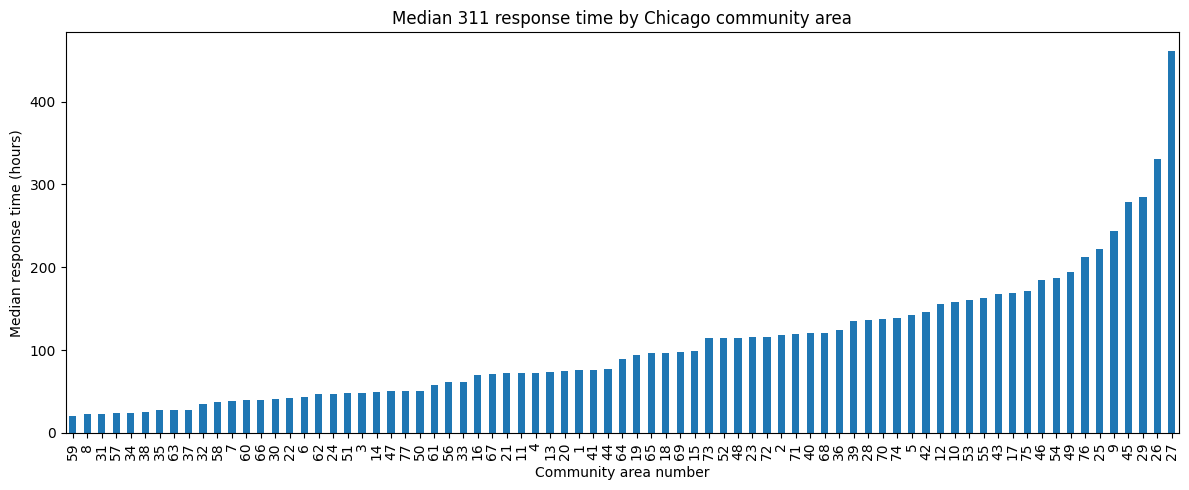

In [ ]:
import matplotlib.pyplot as plt

print(df["created_date"].min(), df["created_date"].max())

skip = ["311 INFORMATION ONLY CALL", "Aircraft Noise Complaint"]
df = df[~df["sr_type"].isin(skip)]
df = df.dropna(subset=["community_area"])
df["community_area"] = df["community_area"].astype(int)
print(df.shape)

by_area = df.groupby("community_area")["response_hours"].agg(["median", "count"])
by_area = by_area[by_area["count"] >= 30].sort_values("median")

plt.figure(figsize=(12, 5))
by_area["median"].plot(kind="bar")
plt.xlabel("Community area number")
plt.ylabel("Median response time (hours)")
plt.title("Median 311 response time by Chicago community area")
plt.tight_layout()
plt.show()

Responsible: Fernando Ramirez

So this will help answer our main question in does the neighborhood change how long you wait? And we took the median response time for each community area that had at least 30 requests. The medians range from about 20 hours in the fastest areas to about 460 hours which is around 19 days in the slowest, and the slowest areas 27, 26, 29 stand out from the rest. This looks like a big gap but it is not a fair comparison yet. These are raw medians and an area with more sidewalk inspections will look slow even if the city treats it the same as everywhere else. So this chart shows that a gap exists not that it is caused by the neighborhood.


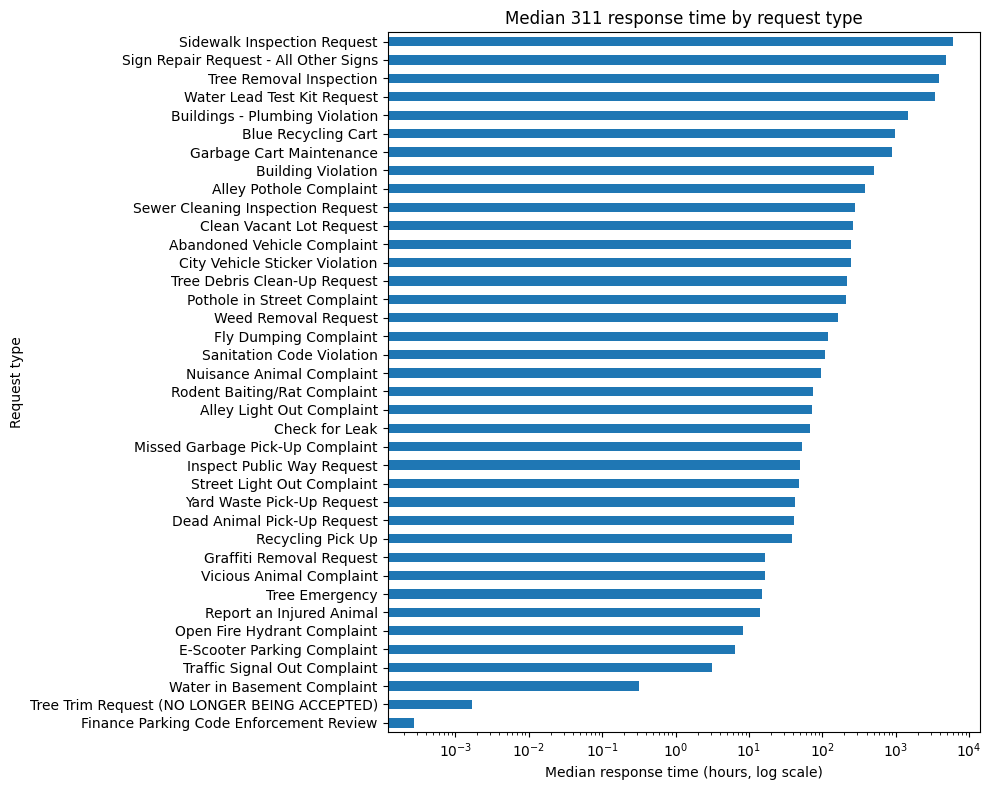

In [ ]:
by_type = df.groupby("sr_type")["response_hours"].agg(["median", "count"])
by_type = by_type[by_type["count"] >= 200].sort_values("median")

plt.figure(figsize=(10, 8))
by_type["median"].plot(kind="barh")
plt.xscale("log")
plt.xlabel("Median response time (hours, log scale)")
plt.ylabel("Request type")
plt.title("Median 311 response time by request type")
plt.tight_layout()
plt.show()

Responsible: Fernando Ramirez

We made this chart to test our guess that request type matters a lot. It uses a log scale because the types are so different. Sidewalk Inspection and Sign Repair take more hours, while Traffic Signal Out and Water in Basement take only a few hours or less. This supports the idea from our introduction that a neighborhood can look slow only because it reports more slow types of requests, so we have to account for type. The two types at the bottom, Tree Trim and Finance Parking Code Review look like office closures which is why we dropped them for ML.


             median  count
month                     
2025-07  142.743889   7419
2025-09  169.495833   6671
2025-11   45.508472   4788
2026-01   26.434444   6674
2026-03   48.895000   5004
2026-05   84.480278   4590


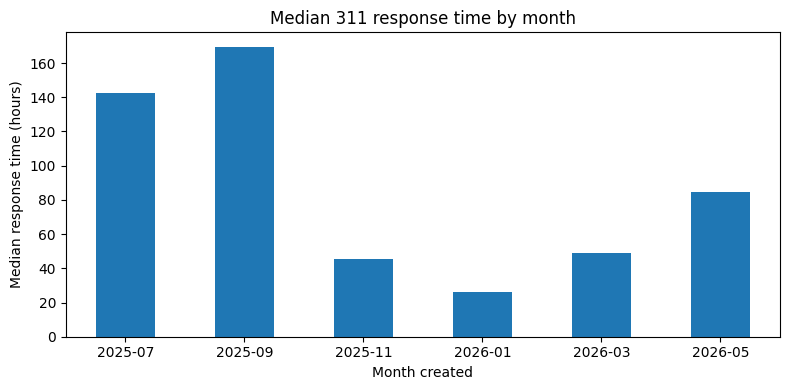

In [ ]:
df["month"] = df["created_date"].dt.to_period("M").astype(str)

by_month = df.groupby("month")["response_hours"].agg(["median", "count"])
print(by_month)

plt.figure(figsize=(8, 4))
by_month["median"].plot(kind="bar", rot=0)
plt.xlabel("Month created")
plt.ylabel("Median response time (hours)")
plt.title("Median 311 response time by month")
plt.tight_layout()
plt.show()

Responsible: Alan Covarrubias

We guessed that response times change with the season. We wanted to know if the city is slower at certain times of year. Medians were highest in July and September 2025 about 143 and 169 hours and lowest in January 2026 about 26 hours. To check that this wasn't just a change in request types, we looked at potholes alone. They showed the same pattern, from about 678 and 738 hours in summer down to 120 in January and 73 in March. So the season seems to matter, but we can't say why. One limit is that we only kept closed requests, so the newest months may look faster than they really are.

In [ ]:
one = df[df["sr_type"] == "Pothole in Street Complaint"]
print(one.groupby("month")["response_hours"].agg(["median", "count"]))

             median  count
month                     
2025-07  678.258056    384
2025-09  738.068611    195
2025-11  334.105000    157
2026-01  120.383889    458
2026-03   72.959028    384
2026-05  277.699028    590


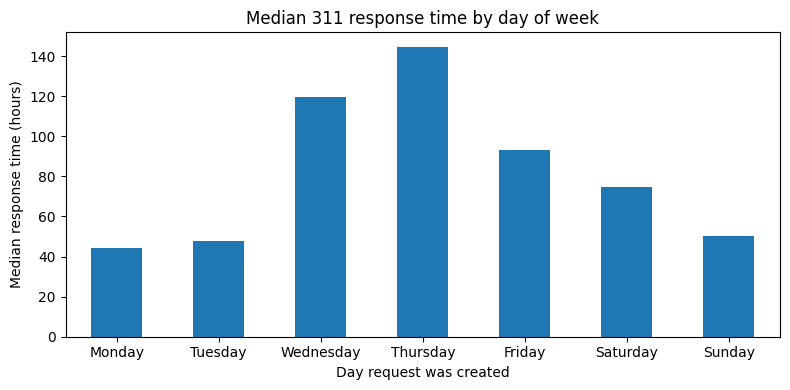

In [ ]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df["weekday"] = df["created_date"].dt.day_name()
by_day = df.groupby("weekday")["response_hours"].median().reindex(order)

plt.figure(figsize=(8, 4))
by_day.plot(kind="bar", rot=0)
plt.xlabel("Day request was created")
plt.ylabel("Median response time (hours)")
plt.title("Median 311 response time by day of week")
plt.tight_layout()
plt.show()

Responsible: Alan Covarrubias

We guessed that requests made on weekends wait longer, because fewer people work then. The graph did not show that. Wednesday and Thursday were the slowest. When we checked we found a problem with our sample. Each Thursday in our data comes from July 2025, which was our slowest month, and the other days come from different months. So this graph is really showing month, not weekday. We can't make any claims about weekdays. In the final project we will sample full weeks to fix this.

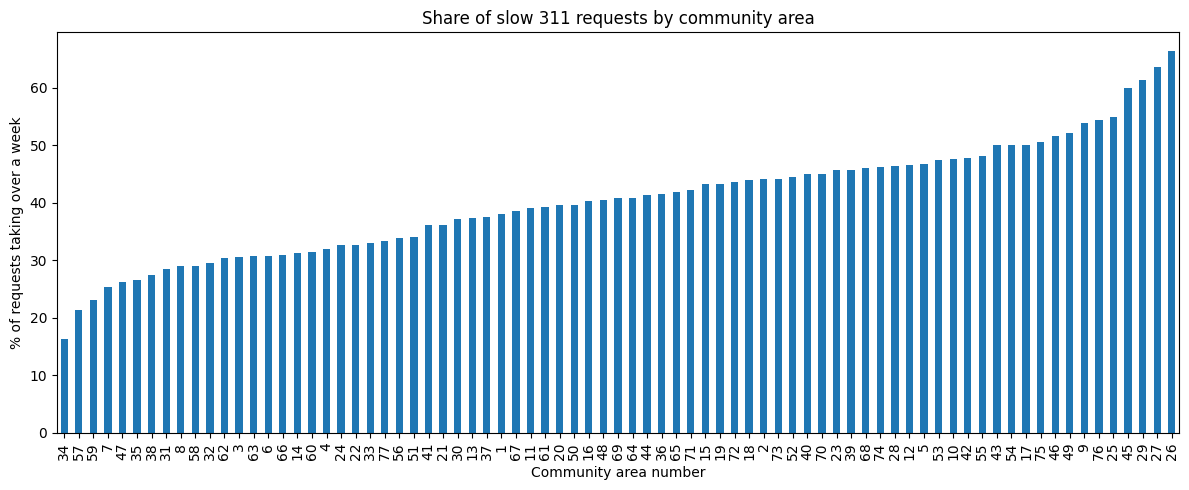

In [ ]:
df["slow"] = df["response_hours"] > 168
slow_share = df.groupby("community_area")["slow"].agg(["mean", "count"])
slow_share = slow_share[slow_share["count"] >= 30].sort_values("mean")

plt.figure(figsize=(12, 5))
(slow_share["mean"] * 100).plot(kind="bar")
plt.xlabel("Community area number")
plt.ylabel("% of requests taking over a week")
plt.title("Share of slow 311 requests by community area")
plt.tight_layout()
plt.show()

Responsible: Fernando Ramirez

So medians can be thrown off by a few very long requests so we also checked what percent of requests in each area took more than a week to close. The answer changes a lot depending on where you live. In the best area 34, only about 16% of requests took over a week, while in the worst area 26 about 66% did. Areas 26, 27, and 29 are near the top and they were also among the slowest on our median chart so both charts point to the same neighborhoods. This does not prove those neighborhoods are treated unfairly cause some request types like sidewalk inspections are slow everywhere, and an area that files more of them will look slow anyway. In the final project we will compare requests of the same type to see if the gap still shows up.


In [ ]:
print(pd.crosstab(df["weekday"], df["month"]))

month      2025-07  2025-09  2025-11  2026-01  2026-03  2026-05
weekday                                                        
Friday           0        0        0        0        0     1859
Monday           0      237     2612     1033     1475        0
Saturday         0        0     1104        0        0     1302
Sunday           0        0     1072        0      837     1429
Thursday      2735        0        0        0        0        0
Tuesday       1556     3429        0     2742     2692        0
Wednesday     3128     3005        0     2899        0        0


# Machine Learning Analyses

For both analyses we asked the same question: if we already know the request type and the month, does knowing the community area help predict how long a request will take? If area adds nothing, then the gaps in our area charts are probably just explained by type mix and season. If it does add something, then there is something about the neighborhood itself worth looking into.

We set both up the same way so they are easy to compare. We dropped the two request types that look like office closures (Tree Trim Request and Finance Parking Code Enforcement Review). All features are categories, so we one hot encoded them. We treated community area as a category and not a number, since area 30 is not "more" than area 29. We split the data 80/20 into training and test sets with a fixed random seed, and every model was trained and scored on the exact same rows. For each analysis we trained two random forests, one with only request type and month, and one that also includes community area. Then we compared both to a simple baseline.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, accuracy_score, f1_score

d = df[~df["sr_type"].isin(["Tree Trim Request (NO LONGER BEING ACCEPTED)",
                            "Finance Parking Code Enforcement Review"])].copy()
d["community_area"] = d["community_area"].astype(str)
d["log_hours"] = np.log10(d["response_hours"])

def make_pipe(cols, model):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cols)])
    return Pipeline([("pre", pre), ("model", model)])

feats_all = ["sr_type", "community_area", "month"]
feats_type = ["sr_type", "month"]

X_train, X_test, y_train, y_test, s_train, s_test = train_test_split(
    d[feats_all], d["log_hours"], d["slow"], test_size=0.2, random_state=42)

base_pred = np.full(len(y_test), y_train.median())
print("Regression baseline MAE (log10 hours):", round(mean_absolute_error(y_test, base_pred), 3))

for name, cols in [("type + month only", feats_type), ("type + month + community area", feats_all)]:
    reg = make_pipe(cols, RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42))
    reg.fit(X_train[cols], y_train)
    print("Regression,", name, "MAE:", round(mean_absolute_error(y_test, reg.predict(X_test[cols])), 3))



Regression baseline MAE (log10 hours): 1.031
Regression, type + month only MAE: 0.671
Regression, type + month + community area MAE: 0.622


## ML Analysis 1: Predicting response time (regression)

Responsible: Rishi Shah

In this analysis we predicted the response time itself. We used the log (base 10) of the hours instead of raw hours, because response times go from a few minutes to several months. Without the log, a handful of very long requests would control the whole model. We scored the models with mean absolute error (MAE) on the log scale. An MAE of 1 means the prediction is usually off by a factor of 10, and an MAE of 0.5 means it is off by a factor of about 3. Our baseline guesses the training median for every request.

| Model | MAE (log10 hours) | Typical error |
|---|---|---|
| Baseline (median) | 1.031 | about 10.7x off |
| Type + month | 0.671 | about 4.7x off |
| Type + month + community area | 0.622 | about 4.2x off |

Type and month alone cut the error by a lot compared to the baseline, which matches our chart showing request type is the biggest driver. Adding community area lowered the MAE by another 0.049, about 7% less error than the type and month model. That is small, but it means area has some information that type and month don't already cover. Even the best model is still off by about 4x on a typical request, so a lot of what decides response time is not in our data, like crew availability, weather, or how bad the problem is.

In [ ]:
maj = s_train.mode()[0]
print("Classifier baseline accuracy:", round(accuracy_score(s_test, np.full(len(s_test), maj)), 3))

for name, cols in [("type + month only", feats_type), ("type + month + community area", feats_all)]:
    clf = make_pipe(cols, RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42))
    clf.fit(X_train[cols], s_train)
    p = clf.predict(X_test[cols])
    print("Classifier,", name, "accuracy:", round(accuracy_score(s_test, p), 3), "F1:", round(f1_score(s_test, p), 3))

Classifier baseline accuracy: 0.585
Classifier, type + month only accuracy: 0.845 F1: 0.815
Classifier, type + month + community area accuracy: 0.861 F1: 0.834


## ML Analysis 2: Predicting slow requests (classification)

Responsible: Rishi Shah

In this analysis we turned the question into yes or no: will a request take longer than a week (168 hours) to close? This matches our "share of slow requests" chart, and it is easier to explain than a log scale. It also doesn't depend on getting the exact number of hours right. Our baseline always guesses the most common answer in the training data, which is "not slow." We report accuracy, and also F1, because accuracy alone can look good just from guessing the bigger group.

| Model | Accuracy | F1 (slow) |
|---|---|---|
| Baseline (always "not slow") | 0.585 | 0.000 |
| Type + month | 0.845 | 0.815 |
| Type + month + community area | 0.861 | 0.834 |

The baseline gets 58.5% right, so about 41.5% of requests in the test set took over a week. Type and month bring accuracy up to 84.5%. Adding community area brings it up again, to 86.1% accuracy and 0.834 F1, a gain of about 1.6 points of accuracy and 1.9 points of F1. That's the same pattern as Analysis 1: area helps, but only a little compared to type.

## What the two analyses tell us together

Both models agree. Request type and month explain most of what we can predict, and community area adds a small but consistent improvement on top. So the gaps in our area charts are not completely explained by type mix and season. We have to be careful, though. This shows that area helps predict response time, not that the city treats neighborhoods unfairly. Area could be standing in for other things, like how much each area's crews have to handle, ward differences, or how severe the problems in an area tend to be. There are also limits to how we tested it. We used one train/test split with no cross-validation, so part of the gain could be luck in how the rows were split. Month is also mixed up with our sampling windows, as we found with weekdays. For the final project we plan to use cross-validation, measure how much area matters with permutation importance, add a simple linear regression for comparison, and see if the area effect lines up with Census income.

# Reflection

Most challenging part:

Getting the data. The full dataset has millions of rows and the portal kept timing out, so we had to pull small windows through the API with a 15,000 row limit. That led to our biggest problem, which is that weekday and month got mixed together in the sample.

Initial insights:

Request type is by far the biggest driver of response time. Response times also differ by season, and potholes show the same seasonal pattern on their own. Community areas differ a lot in raw medians and in the share of slow requests, but some of that is likely type mix. Models that include area do slightly better than those without it.

Concrete results:

Yes. We have cleaned data in 35,146 requests, charts for area, type, month and slow share, and two ML comparisons against baselines. The main result is that area adds a small but consistent gain beyond type and month. We can’t yet say neighborhoods are treated unequally.

Biggest current problems:

(1) The sample covers only about three days per window and may not be random, so weekday can’t be studied.

(2) We only kept closed requests, so recent windows may look faster than they are.

(3) We haven’t joined income data.

(4) The area charts are not adjusted for request type.

On track?

Mostly. The core question and analysis pipeline are working. The main thing that needs more time is a better sample and the Census join.

Worth continuing?

Yes. There is a clear pattern to investigate and the results are not trivial: area adds predictive value on top of type and month. The next step is to make that comparison fair and to test whether it relates to income.



# Next Steps

- Re-sample full weeks so weekday and month are no longer mixed, then redo the weekday analysis.

- Join Census income by community area and test whether lower income areas wait longer for the same request type.

- Compare areas fairly by comparing each request to the typical time for its type, then averaging by area.

- Strengthen the ML section with cross-validation, permutation or feature importance for area, and a simple model such as linear regression as an additional baseline.

- Handle still-open requests so the newest windows are not biased toward fast ones.

- Add area names and a map to make the area results easier to read.
